In [8]:
import pandas as pd 
import numpy as np
import nibabel as nib
import ants
import torch
import matplotlib.pyplot as plt
import seaborn as sns
import plotly
plotly.tools.set_credentials_file(username='Qqin', api_key='GFe6E0uLlZmHtoobrxiv')
import plotly.plotly as py
import plotly.graph_objs as go

from matplotlib.backends.backend_pdf import PdfPages

sns.set("paper", font_scale=1.8)
sns.set_style("ticks", {"xtick.major.size": 0,
                        "ytick.major.size": 0,
                        'font.family': ['sans-serif']})
%matplotlib inline

In [9]:
bids = pd.read_table('results/bids_ready_datasets_annotation.xls')

bids = bids.loc[(bids.age <= 8) & (bids.tesla != 'None'), :]
bids.loc[bids.tesla==3, 'tesla'] = bids.loc[bids.tesla==3, 'tesla'].astype(np.int32)

machine_platform = bids.apply(lambda x: "%s-%s-%.1fT" % (x[1], x[2], round(float(x[3]), 2)), axis=1)
print(machine_platform.value_counts())
print('-'*100)
print(bids.shape)
print(bids.columns)
bids.loc[:, 'merge_machine_info'] = machine_platform

SIEMENS-Avanto-1.5T                        872
GE MEDICAL SYSTEMS-DISCOVERY MR750-3.0T    547
SIEMENS-Skyra-3.0T                         202
dtype: int64
----------------------------------------------------------------------------------------------------
(1621, 17)
Index(['age', 'machine', 'platform', 'tesla', 't1', 't1s', 't2f', 't2', 'dwi',
       'adc', 'gender', 'Cyst', 'Leukomalacia', 'Hemorrhage',
       'Myelin or Develop', 'Expansion', 'Lesion'],
      dtype='object')


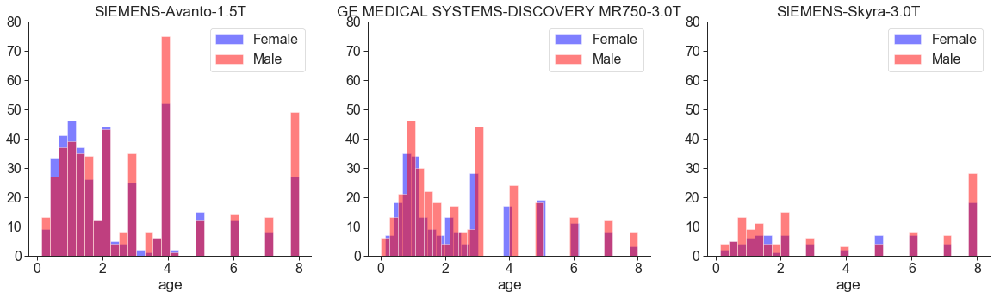

In [4]:
fig = plt.figure(figsize=(20, 5))
for index, platform in enumerate(bids.merge_machine_info.unique()):
    plt.subplot(1, 3, index+1)
    for color, gender in enumerate(bids.gender.unique()):
        sns.distplot(bids.age[(bids.gender==gender) & 
                              (bids.merge_machine_info==platform)], 
                     bins=30, kde=False, 
                     color=['blue', 'red'][color], 
                     hist_kws={"alpha":0.5}, label=gender)
        plt.ylim([0, 80])
        plt.title(platform)
    plt.legend()
    sns.despine()
plt.savefig('results/Figure1_2.pdf')

# Case study of PVL

We shall select different PVL patients with various levels of lesions. We select one typical case with 4 symptoms: Expansion, Lesion, Leukomalacia, Hemorrhage. 

In [10]:
case1 = bids.loc[(bids.Expansion==1) & (bids.Lesion == 1) & (bids.Leukomalacia == 1) &
                 (bids.Hemorrhage==1) & (bids.Cyst==0) & (bids.loc[:, "Myelin or Develop"]==0), :]

In [11]:
from skimage import exposure
from skimage.restoration import denoise_wavelet
from matplotlib import gridspec

def enhan(in_file, clip_limit=0.010):
    import numpy as np
    import nibabel as nb
    import os.path as op
    from skimage import exposure, img_as_int
    from nipype.utils import NUMPY_MMAP
    #im = nb.load(in_file, mmap=NUMPY_MMAP)
    #imdata = im.get_data()    
    im = ants.image_read(in_file)
    brain_mask = ants.get_mask(im)
    im = im.crop_image(brain_mask, label=1)
    im = im.denoise_image()
    imdata = im.numpy()
    imshape = im.shape

    immin = imdata.min()
    imdata = (imdata - immin).astype(np.uint16)

    adapted = exposure.equalize_adapthist(
        denoise_wavelet(imdata.reshape(imshape[0], -1)), clip_limit=clip_limit)
    return brain_mask, adapted.reshape(imshape)

/home/qinqian/.local/lib/python3.6/site-packages/pywt/_multilevel.py:408: FutureWarning:

Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.

/home/qinqian/.local/lib/python3.6/site-packages/skimage/util/dtype.py:135: UserWarning:

Possible precision loss when converting from float64 to uint16



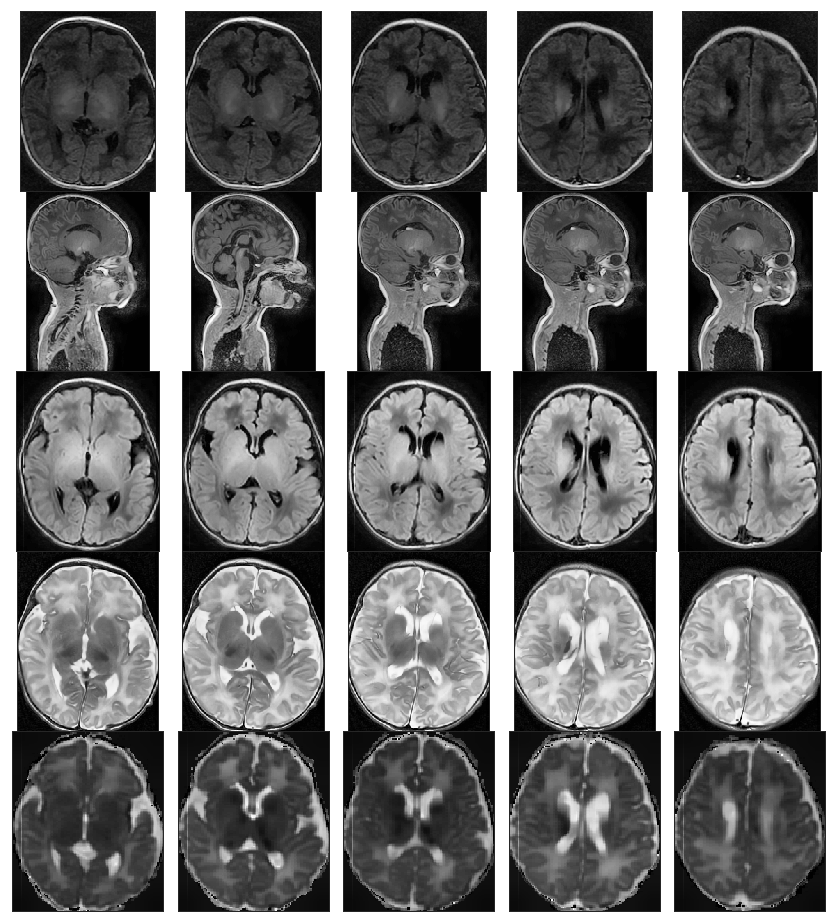

In [7]:
ncol = 5
nrow = 5
plt.figure(figsize=((ncol-0.4)*2.5, (nrow)*2.5))
gs = gridspec.GridSpec(5, 5, wspace=0, hspace=0, top=1, bottom=0, left=0, right=1)

for row_index, modality in enumerate(['t1', 't1s', 't2f', 't2', 'adc']):
    image_mask, image_enhan = enhan(case1.iloc[0, :].loc[modality])    
    if row_index != 1:
        slices = [8, 9, 10, 11, 12]        
    else:
        slices = [40, 50, 60, 61, 62]
    for col_index, slice_num in enumerate(slices):
        ax = plt.subplot(gs[row_index, col_index])
        ax.set_aspect('equal')
        if row_index == 1:
            ax.imshow(np.rot90(image_enhan[slice_num, :, :]), interpolation='nearest', cmap=plt.cm.gray)
        else:
            ax.imshow(np.rot90(image_enhan[:, :, slice_num]), interpolation='nearest', cmap=plt.cm.gray)
        ax.axis('image')
        ax.set_xticks([])
        ax.set_yticks([])

## ANTSpy plot without denoising

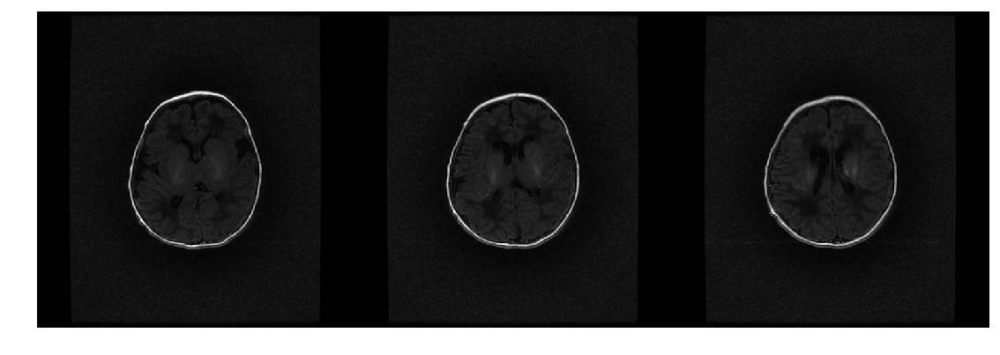

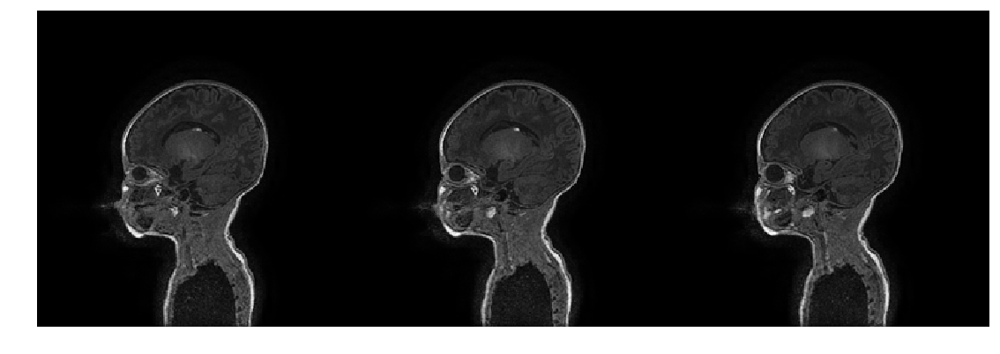

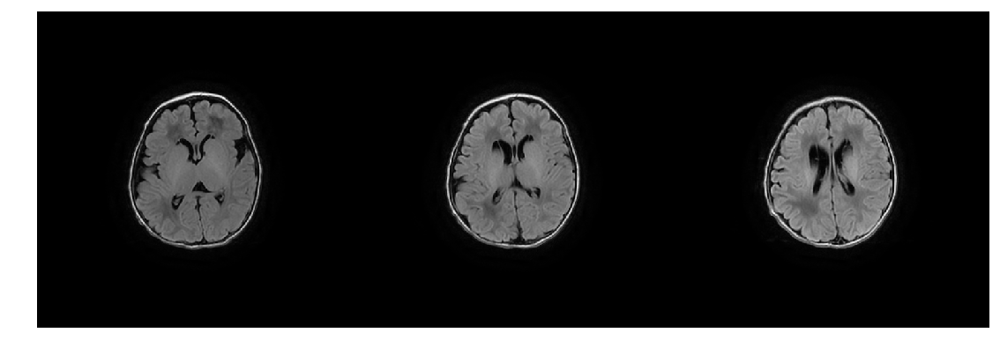

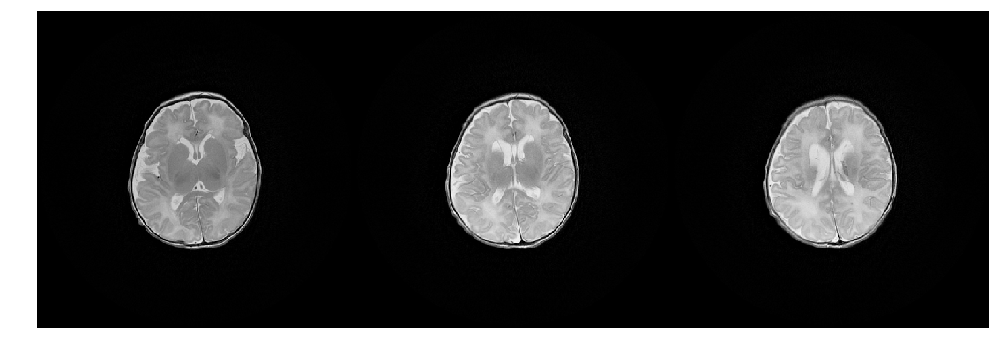

In [12]:
for index, modality in enumerate(case1.columns[4:8]):
    #print(case1.iloc[0, ].loc[modality])
    image = ants.image_read(case1.iloc[0, ].loc[modality])
    if index == 1:
        image.plot(axis=0, slices=(60, 61, 62), ncol=3, figsize=5)        
    else:
        image.plot(axis=2, slices=(9, 10, 11), ncol=3, figsize=5)

## Add skull stripping with BET

In [13]:
t2_file = case1.iloc[0, ].loc['t2']
t2_prefix = t2_file.replace('.nii.gz', '_processed')

!bet $t2_file $t2_prefix -m -R -f 0.4

In [6]:
t2_file

'../../../new_sequence/source/sub-22/anat/sub-22_run-02_T2w.nii.gz'

## Registration to template from Imperial London College

In [14]:
image_modality_dict_case = {}
image_modality_dict_case['t2'] = ants.image_read(t2_file)
image_modality_dict_case['t2'] = ants.resample_image(image_modality_dict_case['t2'], (1,1,1), use_voxels=False)

image_modality_dict_case['mask'] = ants.image_read(f'{t2_prefix}_mask.nii.gz')
image_modality_dict_case['mask'] = ants.resample_image(image_modality_dict_case['mask'], (1,1,1), use_voxels=False)

for modality in ['t1', 't1s', 't2f', 'adc']:
    image_modality_dict_case[modality] = ants.image_read(case1.iloc[0, :].loc[modality])
    image_modality_dict_case[modality] = ants.registration(image_modality_dict_case['t2'], 
                                                      image_modality_dict_case[modality], 
                                                      type_of_transform='Rigid')
    image_modality_dict_case[modality] = image_modality_dict_case[modality]['warpedmovout']

In [15]:
for modality in ['t2','t1', 't1s', 't2f', 'adc', 'mask']: 
    image_modality_dict_case[modality] = image_modality_dict_case[modality] * image_modality_dict_case['mask']
    image_modality_dict_case[modality] = image_modality_dict_case[modality].crop_image(image_modality_dict_case['mask'])

In [16]:
def enhan_ants_image(ants_image, mask, clip_limit=0.015):
    import numpy as np
    from skimage import exposure, img_as_int  
    im = ants_image.denoise_image()
    imdata = im.numpy()
    imshape = im.shape

    immin = imdata.min()
    imdata = (imdata - immin).astype(np.uint16)

    adapted = exposure.equalize_adapthist(
        denoise_wavelet(imdata.reshape(imshape[0], -1)), clip_limit=clip_limit)
    
    adapted_image = adapted.reshape(imshape)
    return ants.make_image(mask.shape, voxval=adapted_image, 
                           spacing=(1,1,1), 
                           direction=ants.get_direction(mask), 
                           origin=ants.get_origin(mask))

/home/qinqian/.local/lib/python3.6/site-packages/pywt/_multilevel.py:408: FutureWarning:

Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.

/home/qinqian/.local/lib/python3.6/site-packages/skimage/util/dtype.py:135: UserWarning:

Possible precision loss when converting from float64 to uint16

/home/qinqian/.local/lib/python3.6/site-packages/numpy/lib/type_check.py:546: DeprecationWarning:

np.asscalar(a) is deprecated since NumPy v1.16, use a.item() instead



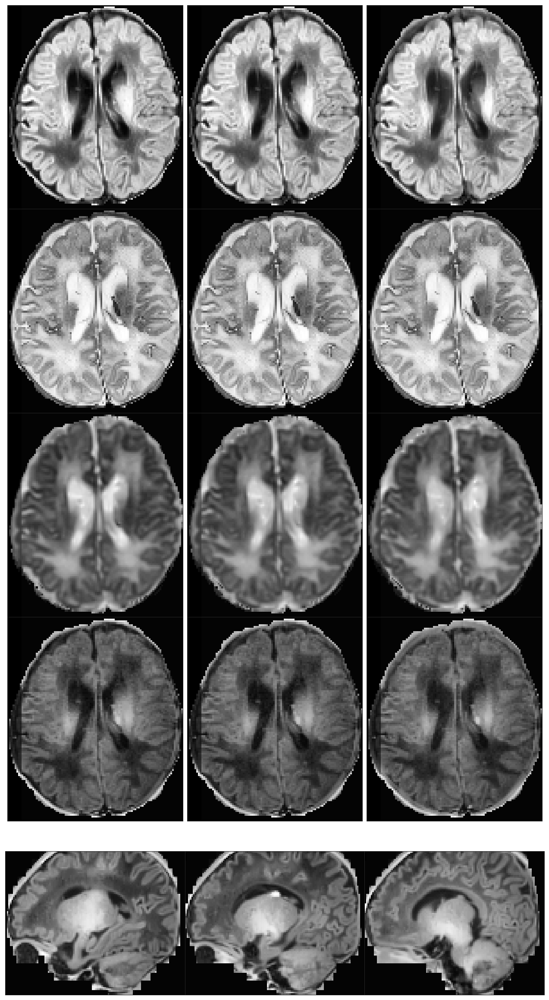

In [17]:
ncol = 3
nrow = 5
plt.figure(figsize=((nrow-2.2)*8, (ncol)*14.5))
gs = gridspec.GridSpec(nrow, ncol, wspace=0, hspace=0)
for row_index, i in enumerate(['t2f', 't2', 'adc', 't1', 't1s']):
    image_enhan = enhan_ants_image(image_modality_dict_case[i], image_modality_dict_case['mask']) 
#     if i == 't1s':
#         fig = image_enhan.plot(axis=0, slices=(60, 61, 62), ncol=3, figsize=8, filename='results/FigureS1_%s.pdf' % i)  
#     else:
#         fig = image_enhan.plot(axis=2, slices=(60, 61, 62), ncol=3, figsize=8, filename='results/FigureS1_%s.pdf' % i)
    if i != 't1s':
        slices = [60, 61, 62]
    else:
        slices = [32, 36, 40]        
    for col_index, sl in enumerate(slices):
        ax = plt.subplot(gs[row_index, col_index])
        ax.set_aspect('equal')
        if i != 't1s':
            ax.imshow(np.rot90(image_enhan[:, :, sl][::-1, :]), interpolation='nearest', cmap=plt.cm.gray) 
        else:
            ax.imshow(np.rot90(image_enhan[sl, :, :][::-1, :]), interpolation='nearest', cmap=plt.cm.gray)             
        ax.axis('image')
        ax.set_xticks([])
        ax.set_yticks([])
plt.savefig('results/FigureS1.pdf')

In [218]:
case1.iloc[0, :]

age                                                             2.85714
machine                                              GE MEDICAL SYSTEMS
platform                                                DISCOVERY MR750
tesla                                                                 3
t1                    ../../../new_sequence/source/sub-22/anat/sub-2...
t1s                   ../../../new_sequence/source/sub-22/anat/sub-2...
t2f                   ../../../new_sequence/source/sub-22/anat/sub-2...
t2                    ../../../new_sequence/source/sub-22/anat/sub-2...
dwi                   ../../../new_sequence/source/sub-22/dwi/sub-22...
adc                   ../../../new_sequence/source/sub-22/dwi/sub-22...
gender                                                             Male
Cyst                                                                  0
Leukomalacia                                                          1
Hemorrhage                                                      

[[1 2 3]
 [4 5 6]]


/home/qinqian/.local/lib/python3.6/site-packages/numpy/lib/type_check.py:546: DeprecationWarning:

np.asscalar(a) is deprecated since NumPy v1.16, use a.item() instead



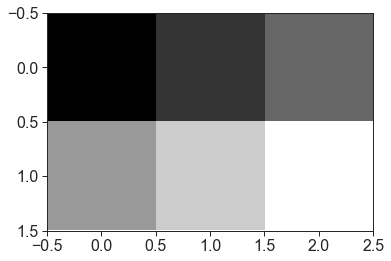

In [410]:
test_imshow = np.array([[1,2,3],[4,5,6]])
print(test_imshow)
plt.imshow(test_imshow, interpolation='nearest', cmap=plt.cm.gray)

## Public template does not work well

In [209]:
template_imperial = ants.image_read('../../../../data/Atlas/Regionalgrowth_and_atlas_Consistent_High_definition_Spatio-tempora/NeonatalAtlas2/template_T2_17.nii.gz')
print(template_imperial.shape)

(117, 159, 126)


In [210]:
ants.get_spacing(template_imperial)

(0.859375, 0.859375, 0.859375)

In [211]:
template_imperial = template_imperial.resample_image((1,1,1), use_voxels=False)

In [212]:
template_imperial = template_imperial.crop_image(template_imperial.get_mask())

In [213]:
print(template_imperial.shape)

(90, 122, 94)


In [214]:
t2 = ants.registration(template_imperial, image_modality_dict['t2'], type_of_transform='Affine')

In [215]:
for i in ['t1', 't1s', 't2f', 'adc']: 
    image_modality_dict[i] = ants.apply_transforms(template_imperial, image_modality_dict[i], t2['fwdtransforms'])

In [216]:
image_modality_dict['t2'] = t2['warpedmovout']
image_modality_dict['mask'] = ants.apply_transforms(template_imperial, image_modality_dict['mask'], t2['fwdtransforms'])

In [222]:
image_modality_dict.keys()

dict_keys(['t2', 'mask', 't1', 't1s', 't2f', 'adc'])

## Build our template 

In [18]:
bids.head()

,age,machine,platform,tesla,t1,t1s,t2f,t2,dwi,adc,gender,Cyst,Leukomalacia,Hemorrhage,Myelin or Develop,Expansion,Lesion,merge_machine_info
2,4.000000,SIEMENS,Avanto,1.5,../../../genetics/source/sub-101/anat/sub-101_...,../../../genetics/source/sub-101/anat/sub-101_...,../../../genetics/source/sub-101/anat/sub-101_...,../../../genetics/source/sub-101/anat/sub-101_...,../../../genetics/source/sub-101/dwi/sub-101_r...,../../../genetics/source/sub-101/dwi/sub-101_r...,Female,0,0,0,0,0,0,SIEMENS-Avanto-1.5T
5,5.000000,GE MEDICAL SYSTEMS,DISCOVERY MR750,3,../../../genetics/source/sub-104/anat/sub-104_...,../../../genetics/source/sub-104/anat/sub-104_...,../../../genetics/source/sub-104/anat/sub-104_...,../../../genetics/source/sub-104/anat/sub-104_...,../../../genetics/source/sub-104/dwi/sub-104_r...,../../../genetics/source/sub-104/dwi/sub-104_r...,Female,0,0,0,0,0,0,GE MEDICAL SYSTEMS-DISCOVERY MR750-3.0T
6,5.000000,SIEMENS,Avanto,1.5,../../../genetics/source/sub-105/anat/sub-105_...,../../../genetics/source/sub-105/anat/sub-105_...,../../../genetics/source/sub-105/anat/sub-105_...,../../../genetics/source/sub-105/anat/sub-105_...,../../../genetics/source/sub-105/dwi/sub-105_r...,../../../genetics/source/sub-105/dwi/sub-105_r...,Female,0,0,0,1,0,0,SIEMENS-Avanto-1.5T
8,2.000000,SIEMENS,Avanto,1.5,../../../genetics/source/sub-107/anat/sub-107_...,../../../genetics/source/sub-107/anat/sub-107_...,../../../genetics/source/sub-107/anat/sub-107_...,../../../genetics/source/sub-107/anat/sub-107_...,../../../genetics/source/sub-107/dwi/sub-107_r...,../../../genetics/source/sub-107/dwi/sub-107_r...,Female,0,0,0,0,0,0,SIEMENS-Avanto-1.5T
9,1.857143,GE MEDICAL SYSTEMS,DISCOVERY MR750,3,../../../genetics/source/sub-108/anat/sub-108_...,../../../genetics/source/sub-108/anat/sub-108_...,../../../genetics/source/sub-108/anat/sub-108_...,../../../genetics/source/sub-108/anat/sub-108_...,../../../genetics/source/sub-108/dwi/sub-108_r...,../../../genetics/source/sub-108/dwi/sub-108_r...,Male,0,0,1,0,0,0,GE MEDICAL SYSTEMS-DISCOVERY MR750-3.0T


In [19]:
bids.loc[bids.age >= 8, 'merge_machine_info'].value_counts()

SIEMENS-Avanto-1.5T                        76
SIEMENS-Skyra-3.0T                         46
GE MEDICAL SYSTEMS-DISCOVERY MR750-3.0T    11
Name: merge_machine_info, dtype: int64

In [20]:
!mkdir -p results/template_candidates

In [21]:
import random

np.random.seed(999)
random.seed(999)

template_candidates = []
for platform in bids.merge_machine_info.unique():
    template_candidates += list(np.random.choice(bids.loc[(bids.age >= 8) & 
                                                          (bids.merge_machine_info == platform), :].index, 3, 
                                                 replace=False))

In [22]:
template_candidates

[63, 1118, 55, 451, 424, 635, 2319, 2937, 2657]

In [204]:
image_modality_dict = {}

In [213]:
for candidate in template_candidates:
    t2_file = bids.loc[candidate, ].loc['t2']
    t2_prefix = t2_file.replace('.nii.gz', '_processed')
    !bet $t2_file $t2_prefix -m -R -f 0.4  

    image_modality_dict[candidate] = {}
    image_modality_dict[candidate]['t2'] = ants.image_read(t2_file)
    image_modality_dict[candidate]['t2'] = ants.resample_image(image_modality_dict[candidate]['t2'], (1,1,1), use_voxels=False)
    image_modality_dict[candidate]['mask'] = ants.image_read(f'{t2_prefix}_mask.nii.gz') 
    image_modality_dict[candidate]['mask'] = ants.resample_image(image_modality_dict[candidate]['mask'], 
                                                                (1,1,1), use_voxels=False)
    for modality in ['t1', 't1s', 't2f', 'adc']:
        image_modality_dict[candidate][modality] = ants.image_read(bids.loc[candidate, ].loc[modality])
        image_modality_dict[candidate][modality] = ants.registration(image_modality_dict[candidate]['t2'], 
                                                                     image_modality_dict[candidate][modality], 
                                                                     type_of_transform='Rigid')
        image_modality_dict[candidate][modality] = image_modality_dict[candidate][modality]['warpedmovout']
    for modality in ['t2', 't1', 't1s', 't2f', 'adc', 'mask']:
        image_modality_dict[candidate][modality] = image_modality_dict[candidate][modality] * image_modality_dict[candidate]['mask']        
        image_modality_dict[candidate][modality] = image_modality_dict[candidate][modality].crop_image(image_modality_dict[candidate]['mask'])

In [215]:
enhan_image_modality_dict = {}
for candidate in template_candidates:
    enhan_image_modality_dict[candidate] = {}
    for i in ['t2', 't1', 't1s', 't2f', 'adc']: 
        enhan_image_modality_dict[candidate][i] = enhan_ants_image(image_modality_dict[candidate][i], 
                                        image_modality_dict[candidate]['mask'])

/home/qinqian/.local/lib/python3.6/site-packages/pywt/_multilevel.py:408: FutureWarning:

Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.

/home/qinqian/.local/lib/python3.6/site-packages/skimage/util/dtype.py:135: UserWarning:

Possible precision loss when converting from float64 to uint16



In [220]:
## select slices
enhan_image_modality_dict.keys()

dict_keys([63, 1118, 55, 451, 424, 635, 2319, 2937, 2657])

In [221]:
view_slices = {}
for patient in enhan_image_modality_dict:
    target_mulmodal_slices = []
    for i in ['t1', 't2', 'adc', 't2f']:
        target_slices = np.vstack([enhan_image_modality_dict[patient][i][:, :, 60], 
                                   enhan_image_modality_dict[patient][i][:, :, 61],
                                   enhan_image_modality_dict[patient][i][:, :, 62]])
        target_mulmodal_slices.append(target_slices)
    target_mulmodal_slices = np.hstack(target_mulmodal_slices)
    sag_target_slices = np.vstack([
                                   enhan_image_modality_dict[patient]['t1s'][32, :, :], 
                                   enhan_image_modality_dict[patient]['t1s'][36, :, :],
                                   enhan_image_modality_dict[patient]['t1s'][40, :, :]])
    view_slices[patient] = [target_mulmodal_slices, sag_target_slices]

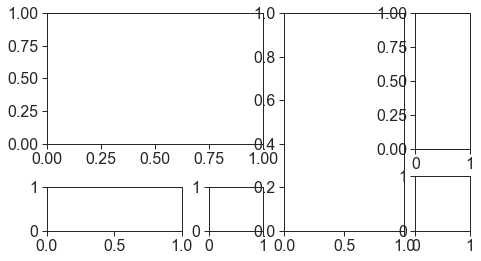

In [203]:
gs1 = gridspec.GridSpec(3, 3)
gs1.update(left=0.0, right=0.5, wspace=0.5, hspace=1)
ax1 = plt.subplot(gs1[:-1, :])
ax2 = plt.subplot(gs1[-1, :-1])
ax3 = plt.subplot(gs1[-1, -1])

gs2 = gridspec.GridSpec(3, 3)
gs2.update(left=0.55, right=0.98, hspace=0.5)
ax4 = plt.subplot(gs2[:, :-1])
ax5 = plt.subplot(gs2[:-1, -1])
ax6 = plt.subplot(gs2[-1, -1])

/home/qinqian/.local/lib/python3.6/site-packages/numpy/lib/type_check.py:546: DeprecationWarning:

np.asscalar(a) is deprecated since NumPy v1.16, use a.item() instead



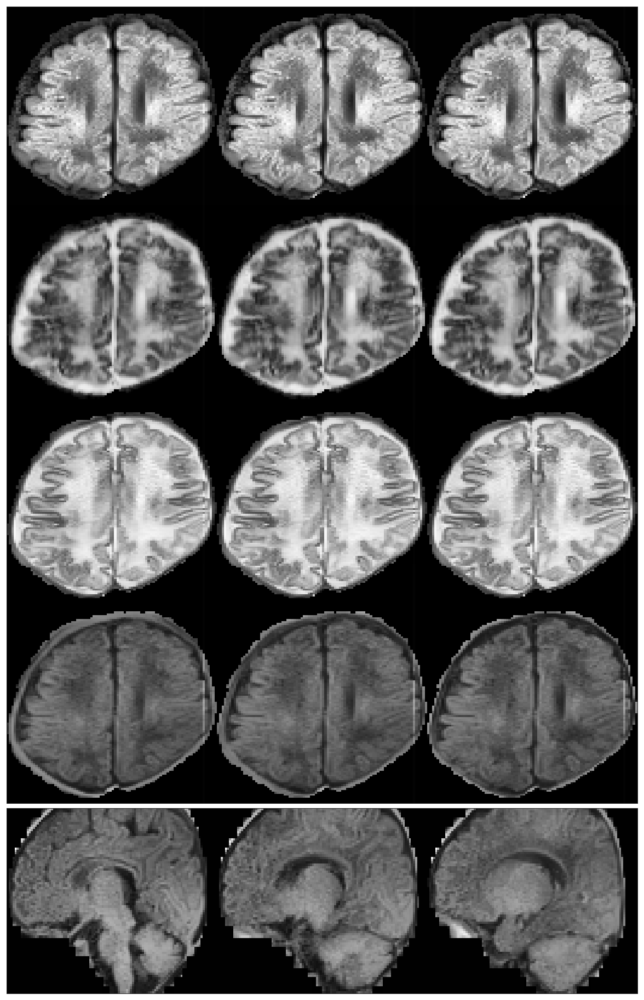

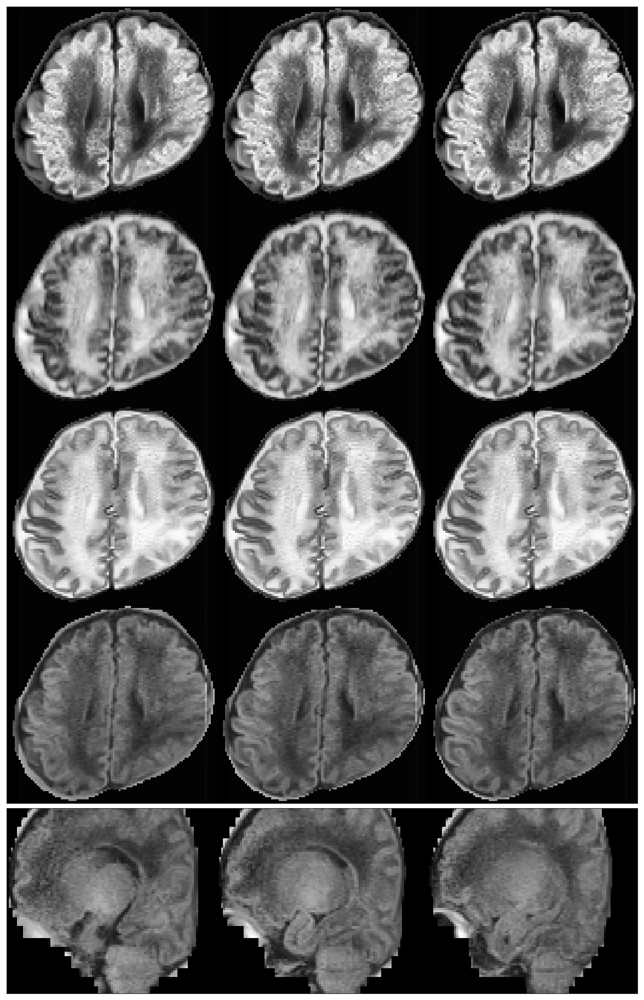

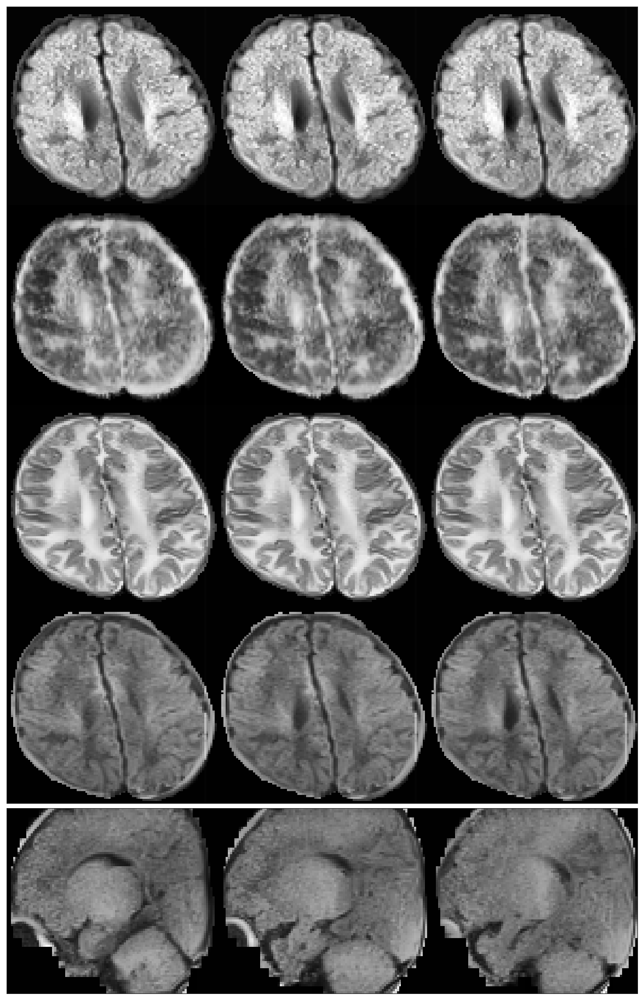

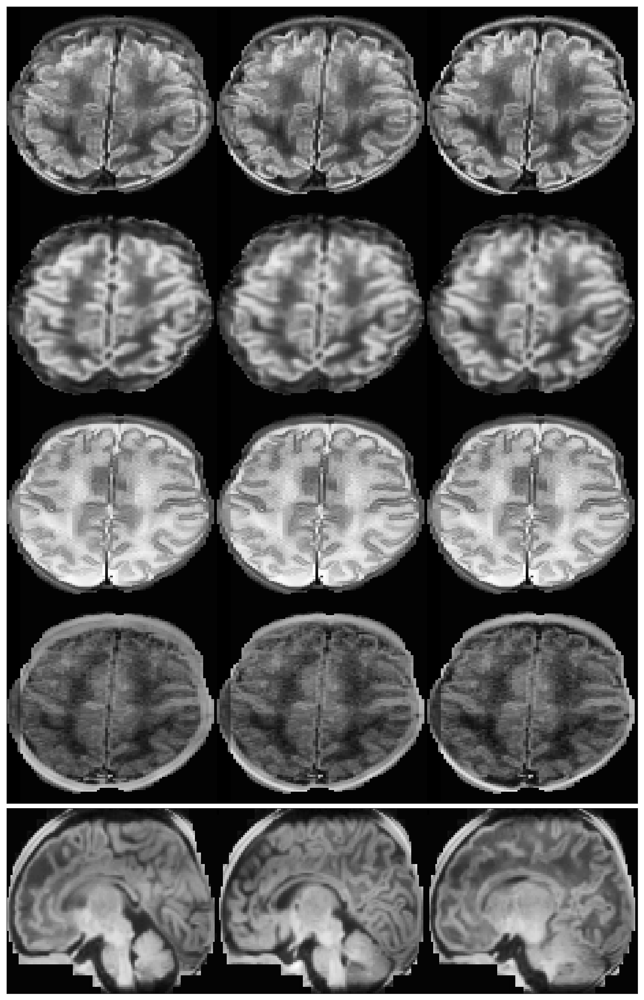

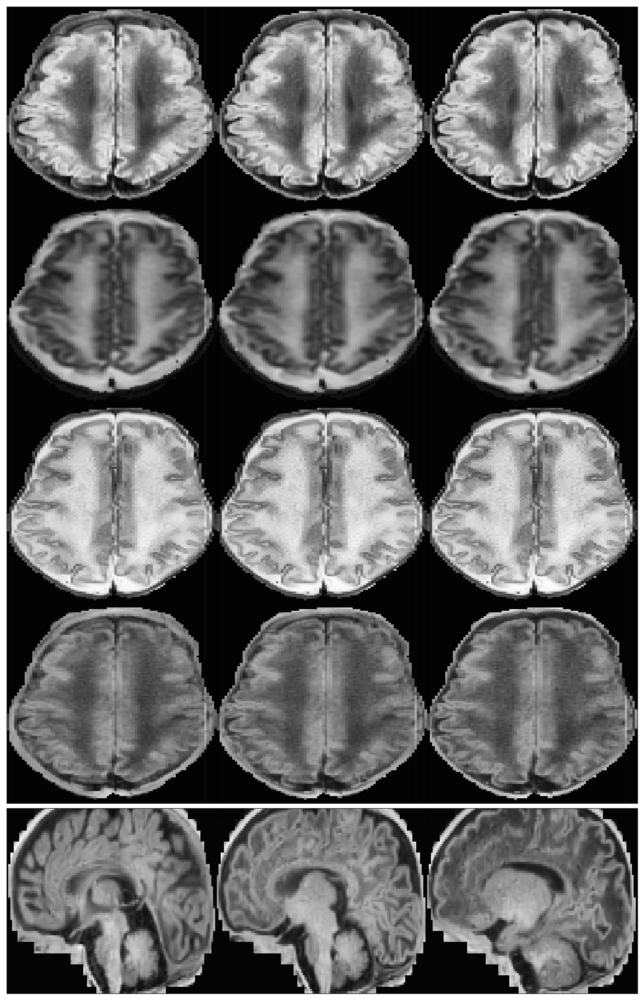

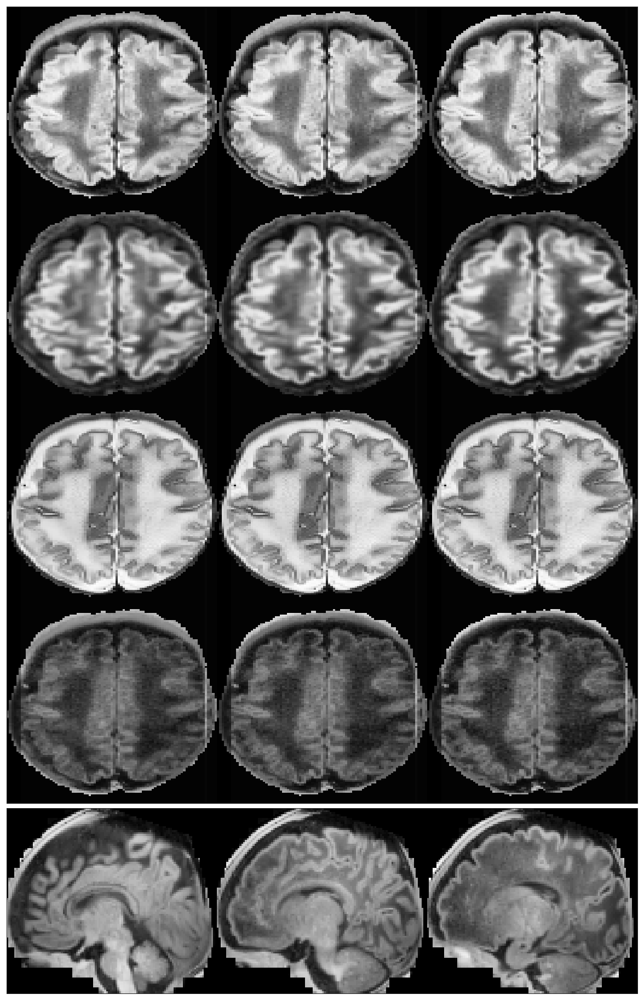

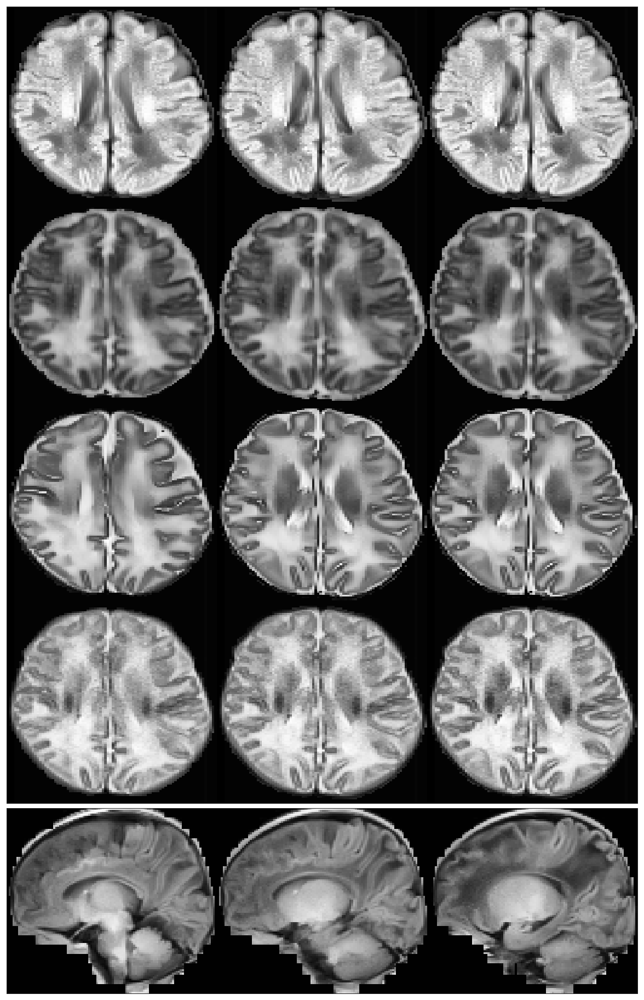

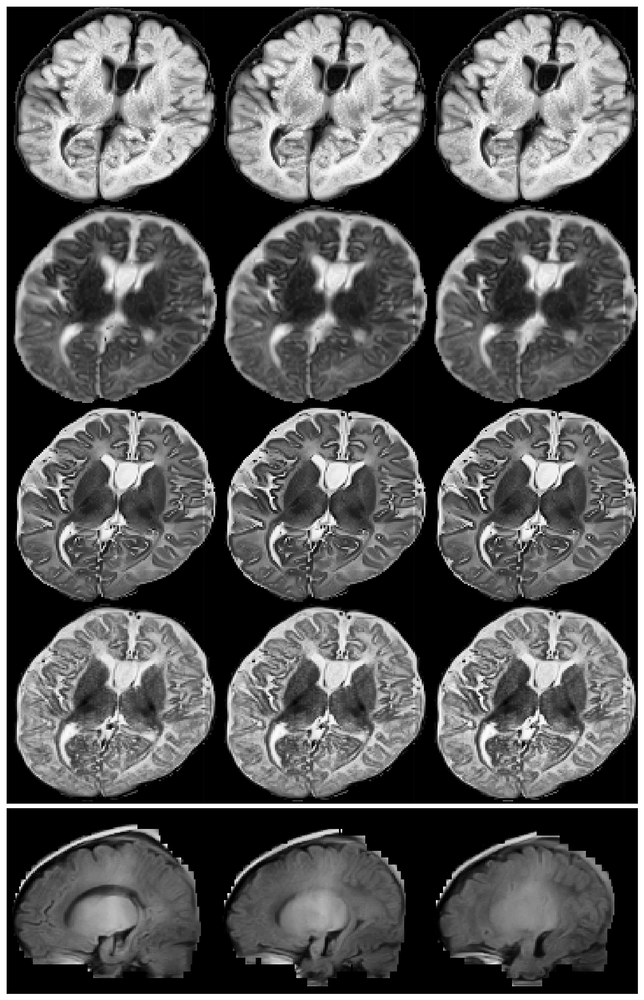

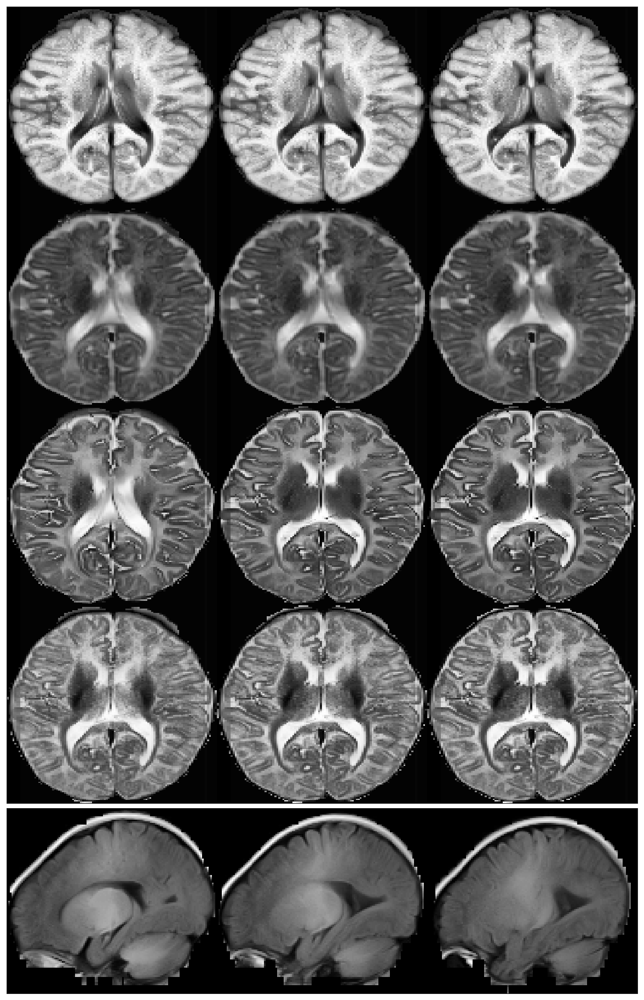

In [267]:
with PdfPages('results/FigureS1_template.pdf') as pdf:
    for i in view_slices:
        fig = plt.figure(figsize=(16, 25))
        gs = gridspec.GridSpec(2, 1, left=0, right=1, 
                               wspace=0.0, hspace=0.01, 
                               top=1, bottom=0, 
                               height_ratios=[4.3,1])

        ax = plt.subplot(gs[0, 0])
        ax.imshow(np.rot90(view_slices[i][0])[:, ::-1], 
                  aspect='auto',
                  #view_slices[i][0].shape[1]*4/view_slices[i][0].shape[0],
                  interpolation='nearest', cmap=plt.cm.gray)
        #ax.axis('image')
        ax.set_xticks([])
        ax.set_yticks([])

        ax = plt.subplot(gs[1, 0])
        ax.imshow(np.rot90(view_slices[i][1])[:, ::-1], 
                  aspect='auto',
                  #view_slices[i][1].shape[1]*4/view_slices[i][1].shape[0],
                  interpolation='nearest', cmap=plt.cm.gray)
        #ax.axis('image')
        ax.set_xticks([])
        ax.set_yticks([])
        pdf.savefig(fig)

In [250]:
for patient in enhan_image_modality_dict.keys():
    for i in ['t1', 't1s', 't2', 'adc', 't2f']:
        ants.image_write(enhan_image_modality_dict[patient][i], 
                         f'results/template_candidates/{patient}_{i}_processed.nii.gz')

In [263]:
from collections import defaultdict
import os
template_df = defaultdict(list)
for patient in enhan_image_modality_dict.keys():    
     for i in ['t1', 't1s', 't2', 'adc', 't2f']:
         template_df[patient].append(os.path.abspath(f'results/template_candidates/{patient}_{i}_processed.nii.gz'))

In [264]:
template_df = pd.DataFrame(template_df, index=['t1', 't1s', 't2', 'adc', 't2f'])

In [268]:
template_df.transpose().to_csv('results/template_candidates/templateInput.csv', sep=',', index=None, header=None)

In [278]:
from ants.viz.render_surface_function import render_surface_function

In [281]:
render_surface_function(enhan_image_modality_dict[63]['t2'],
                        enhan_image_modality_dict[63]['t2'])

In [288]:
from IPython.core.display import HTML
with open('ants_plot.html') as plot_surf:
    display(HTML(plot_surf.read()))